In [10]:
%matplotlib inline

# Solution 4 — Dynamic aperture

Load one ring and scan the transverse amplitudes of on-momentum particles. Complete the particle generation and tracking, then repeat for the other ring with the same settings.

Use a common reference geometric emittance of **10 nm rad in both planes and both rings**. See the [Xsuite dynamic-aperture example](https://xsuite.readthedocs.io/en/latest/dynamic_aperture.html).

### Load a ring

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import xtrack as xt
import xpart as xp

lattice_file = 'ring_dba.json'  # Change to 'ring_dba.json' for the second run.
ring = xt.load(lattice_file)

Loading line from dict:   0%|          | 0/208 [00:00<?, ?it/s]

Done loading line from dict.           


In [12]:
tw = ring.twiss4d()
print('Tunes:', tw.qx, tw.qy)
print('Chromaticities:', tw.dqx, tw.dqy)

Tunes: 14.8000000062968 6.700000004467984
Chromaticities: 0.5000002934880117 0.5000000000516254


### Add an aperture

Install a circular aperture of 10 cm radius at the ring entrance to remove particles whose amplitudes grow large. This aperture is checked once per turn.

In [13]:
ring.insert('aperture_da', xt.LimitEllipse(a=0.10, b=0.10), at=0)

Slicing line:   0%|          | 0/384 [00:00<?, ?it/s]

### Generate particles

Use a polar grid in the first quadrant, with zero initial normalized momenta and $\delta=0$. The reference emittance sets the amplitude scale:

$$
\sigma_{x,\mathrm{ref}}=\sqrt{\beta_x\varepsilon_{\mathrm{ref}}},\qquad
\sigma_{y,\mathrm{ref}}=\sqrt{\beta_y\varepsilon_{\mathrm{ref}}}.
$$

Keep $\varepsilon_{\mathrm{ref}}$ fixed when switching rings; it is a common scale, not their equilibrium emittance.

In [14]:
gemitt_ref = 10e-9  # m rad (geometric), common to both planes and both rings
num_turns = 200

x_normalized, y_normalized, r_xy, theta_xy = xp.generate_2D_polar_grid(
    r_range=(0, 300),
    theta_range=(0, np.pi / 2),
    nr=60, ntheta=15,
)

In [15]:
particles = ring.build_particles(
    method='4d',
    x_norm=x_normalized, px_norm=0,
    y_norm=y_normalized, py_norm=0,
    gemitt_x=gemitt_ref, gemitt_y=gemitt_ref,
    delta=0,
)

### Track

Track for `num_turns` with RF and radiation off. Use `time=True` to measure the tracking time.

In [16]:
ring.track(particles, num_turns=num_turns, time=True)
print(f'Tracking time: {ring.time_last_track:.2f} s')

Tracking time: 4.72 s


### Plot survival

Sort by particle ID to restore the launch order before associating the results with the initial amplitudes.

In [17]:
particles.sort(interleave_lost_particles=True)
survived = particles.state > 0
print('Surviving particles:', np.count_nonzero(survived), '/', len(survived))

Surviving particles: 109 / 900


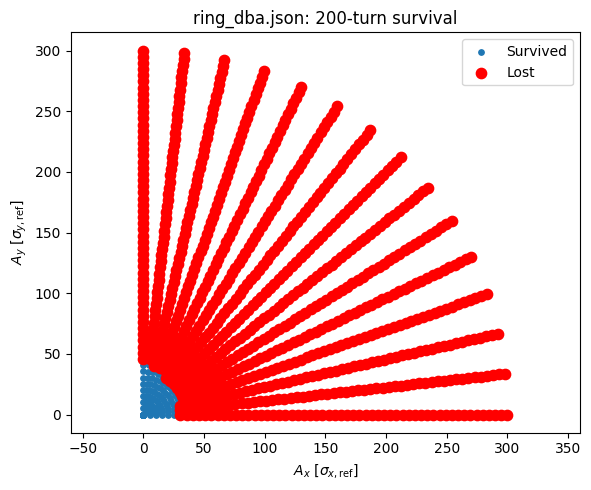

In [18]:
plt.figure(figsize=(6, 5))
plt.scatter(x_normalized[survived], y_normalized[survived],
            color='C0', s=15, label='Survived')
plt.scatter(x_normalized[~survived], y_normalized[~survived],
            color='red', s=55, label='Lost')
plt.xlabel(r'$A_x$ [$\sigma_{x,\mathrm{ref}}$]')
plt.ylabel(r'$A_y$ [$\sigma_{y,\mathrm{ref}}$]')
plt.legend()
plt.title(f'{lattice_file}: {num_turns}-turn survival')
plt.axis('equal')
plt.tight_layout()

### Compare the rings

Repeat with the other JSON file and compare the survival boundaries. Increase the amplitude range if you do not reach losses, and increase the number of turns to check how the boundary changes.

This scan samples one choice of initial betatron phases over a finite number of turns, with an added physical aperture.